# 03 — Final evaluation on the held-out test set
**Project:** Who should be referred for a glucose tolerance test? (see [`docs/problem_definition.md`](../docs/problem_definition.md))

**Protocol**
- This is the **only** notebook that uses the 154 test patients. Nothing here is used to change the models, features or thresholds.
  Changing anything after seeing these results would make the test set just another validation set.
- The models, features and thresholds are loaded exactly as saved in notebook 02 (`models/metadata.json`).
- Each research question is judged against the success criterion written **before modelling**, using
  **paired bootstrap 95 % confidence intervals**.

*Small-sample warning:* 154 patients include only about 54 with diabetes, so every number below has wide uncertainty.
The confidence intervals show how wide.

In [1]:
import sys, json
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.calibration import calibration_curve

from src.data import load_clean, train_test, TARGET, PROJECT_ROOT
from src.models import GuidelineRule, logistic, sensitivity_at_rate

sns.set_theme(style="whitegrid")
train, test = train_test(load_clean())
meta = json.loads((PROJECT_ROOT / "models" / "metadata.json").read_text())
models = {key: joblib.load(PROJECT_ROOT / info["file"]) for key, info in meta["models"].items()}

y_test = test[TARGET].to_numpy()
print(f"Test patients: {len(test)}, with diabetes: {y_test.sum()} ({y_test.mean():.1%})")

Test patients: 154, with diabetes: 54 (35.1%)


## 1. Scores on the test set
The glucose-only baseline is fitted on the **training** data, exactly as in cross-validation. The guideline rule needs no fitting.

In [2]:
glucose_only = logistic(["Glucose"]).fit(train[["Glucose"]], train[TARGET])
scores = {
    "guideline rule": GuidelineRule().predict_proba(test)[:, 1],
    "no-lab model":   models["no_lab"].predict_proba(test[meta["models"]["no_lab"]["features"]])[:, 1],
    "glucose only":   glucose_only.predict_proba(test[["Glucose"]])[:, 1],
    "full model":     models["full"].predict_proba(test[meta["models"]["full"]["features"]])[:, 1],
}
rule_rate = scores["guideline rule"].mean()
print(f"Guideline rule refers {rule_rate:.1%} of test patients")

table = pd.DataFrame({
    name: {"ROC-AUC": roc_auc_score(y_test, s),
           "PR-AUC": average_precision_score(y_test, s),
           "sensitivity at rule's referral rate": sensitivity_at_rate(y_test, s, rule_rate),
           "Brier score": brier_score_loss(y_test, s) if name != "guideline rule" else np.nan}
    for name, s in scores.items()}).T.round(3)
table

Guideline rule refers 31.2% of test patients


,ROC-AUC,PR-AUC,sensitivity at rule's referral rate,Brier score
guideline rule,0.659,0.471,0.519,NaN
no-lab model,0.730,0.553,0.463,0.200
glucose only,0.765,0.595,0.500,0.193
full model,0.813,0.673,0.519,0.175


## 2. The verdicts: paired bootstrap confidence intervals
We resample the 154 test patients with replacement 5,000 times. Each time, we recompute **both** models' scores on the *same*
resampled patients and take the difference. The middle 95 % of those differences is the confidence interval.
**If the interval contains 0, the test set cannot tell the two apart.**

In [3]:
rng = np.random.default_rng(42)
N_BOOT = 5000
boot = {"no-lab − rule (sensitivity at rule rate)": [], "full − glucose (ROC-AUC)": [],
        "full − no-lab (sensitivity at rule rate)": []}
n = len(y_test)
for _ in range(N_BOOT):
    idx = rng.integers(0, n, n)
    yb = y_test[idx]
    if yb.sum() == 0 or yb.sum() == n:
        continue
    rate_b = scores["guideline rule"][idx].mean()
    sens = {k: sensitivity_at_rate(yb, scores[k][idx], rate_b) for k in ["guideline rule", "no-lab model", "full model"]}
    boot["no-lab − rule (sensitivity at rule rate)"].append(sens["no-lab model"] - sens["guideline rule"])
    boot["full − no-lab (sensitivity at rule rate)"].append(sens["full model"] - sens["no-lab model"])
    boot["full − glucose (ROC-AUC)"].append(roc_auc_score(yb, scores["full model"][idx]) - roc_auc_score(yb, scores["glucose only"][idx]))

point = {
    "no-lab − rule (sensitivity at rule rate)": table.loc["no-lab model", "sensitivity at rule's referral rate"] - table.loc["guideline rule", "sensitivity at rule's referral rate"],
    "full − glucose (ROC-AUC)": table.loc["full model", "ROC-AUC"] - table.loc["glucose only", "ROC-AUC"],
    "full − no-lab (sensitivity at rule rate)": table.loc["full model", "sensitivity at rule's referral rate"] - table.loc["no-lab model", "sensitivity at rule's referral rate"],
}
verdicts = pd.DataFrame({
    "difference": point,
    "95% CI low": {k: np.percentile(v, 2.5) for k, v in boot.items()},
    "95% CI high": {k: np.percentile(v, 97.5) for k, v in boot.items()},
    "share of resamples > 0": {k: np.mean(np.array(v) > 0) for k, v in boot.items()},
}).round(3)
verdicts["CI excludes 0?"] = (verdicts["95% CI low"] > 0) | (verdicts["95% CI high"] < 0)
verdicts

,difference,95% CI low,95% CI high,share of resamples > 0,CI excludes 0?
no-lab − rule (sensitivity at rule rate),-0.056,-0.143,0.060,0.156,False
full − glucose (ROC-AUC),0.048,0.004,0.095,0.984,True
full − no-lab (sensitivity at rule rate),0.056,-0.050,0.174,0.816,False


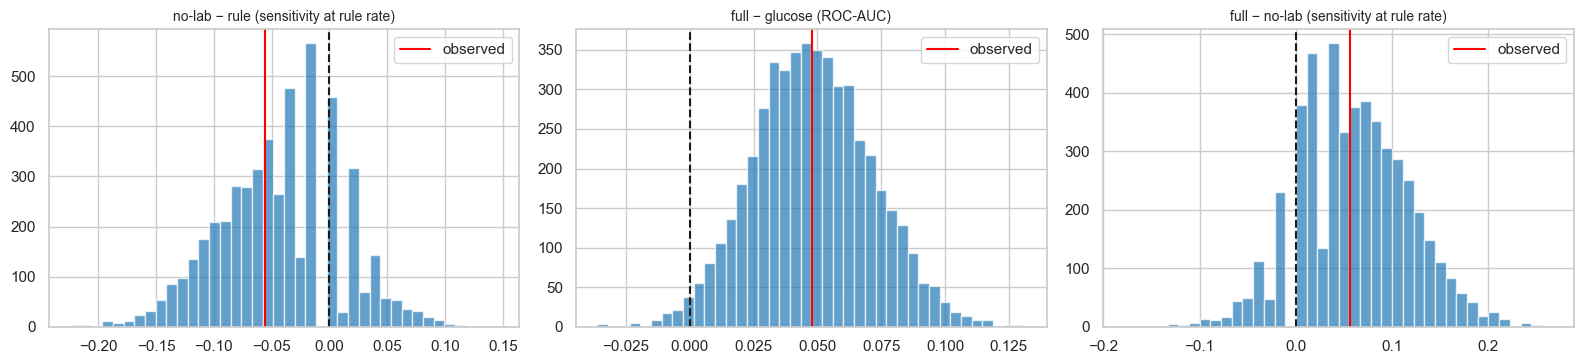

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, (name, values) in zip(axes, boot.items()):
    ax.hist(values, bins=40, color="tab:blue", alpha=0.7)
    ax.axvline(0, color="k", linestyle="--")
    ax.axvline(point[name], color="red", label="observed")
    ax.set_title(name, fontsize=10)
    ax.legend()
plt.tight_layout()
plt.show()

**Reading the verdicts**
- **No-lab model vs rule:** on the test set the model caught **fewer** cases at the rule's referral rate (−5.6 points).
  The CI (−14 to +6 points) includes 0. Together with the cross-validation tie (+1 point), the conclusion is that
  **there's no evidence the no-lab model beats the guideline rule, and it may be slightly worse.**
- **Full model vs glucose alone:** +0.048 ROC-AUC, with a CI of **+0.004 to +0.095** that **excludes 0**. The improvement is real,
  but the lower bound is close to zero, so it could be small.
- **Full vs no-lab at the rule's referral rate:** +5.6 points, but the CI includes 0. Cross-validation suggested +13 points.
  At a single operating point with only 54 cases, each missed or caught patient moves sensitivity by ~2 points, so this metric is noisy.
  ROC-AUC uses all patients and is more stable, and it does show a clear gap (0.81 vs 0.73).
- **Test vs cross-validation:** test scores are a bit lower than CV (full model ROC-AUC 0.81 vs 0.84). That's within normal variation
  for 154 patients, and it is exactly why we keep a test set: CV scores after model selection tend to be slightly optimistic.

## 3. Do the thresholds chosen on training data hold up?
The app will use the thresholds saved in notebook 02. Here we apply them, **unchanged**, to the test patients.

In [5]:
rows = []
for key, label in [("no_lab", "no-lab model"), ("full", "full model")]:
    for t_name, t in meta["models"][key]["thresholds"].items():
        referred = scores[label] >= t
        tp = (referred & (y_test == 1)).sum()
        rows.append({"model": label, "threshold": f"{t_name} ({t:.3f})",
                     "referral rate": referred.mean(),
                     "sensitivity": tp / y_test.sum(),
                     "PPV (share of referred with diabetes)": tp / max(referred.sum(), 1),
                     "missed cases": int((~referred & (y_test == 1)).sum())})
referred_rule = scores["guideline rule"] == 1
rows.append({"model": "guideline rule", "threshold": "Age≥35 & BMI≥25", "referral rate": referred_rule.mean(),
             "sensitivity": (referred_rule & (y_test == 1)).sum() / y_test.sum(),
             "PPV (share of referred with diabetes)": y_test[referred_rule].mean(),
             "missed cases": int((~referred_rule & (y_test == 1)).sum())})
pd.DataFrame(rows).set_index(["model", "threshold"]).round(3)

referral rate  sensitivity  \
model          threshold                                              
no-lab model   matched_rate (0.422)              0.338        0.519   
               high_sensitivity (0.283)          0.545        0.759   
full model     matched_rate (0.418)              0.338        0.556   
               high_sensitivity (0.250)          0.532        0.870   
guideline rule Age≥35 & BMI≥25                   0.312        0.519   

                                         PPV (share of referred with diabetes)  \
model          threshold                                                         
no-lab model   matched_rate (0.422)                                      0.538   
               high_sensitivity (0.283)                                  0.488   
full model     matched_rate (0.418)                                      0.577   
               high_sensitivity (0.250)                                  0.573   
guideline rule Age≥35 & BMI≥25                                           0.583   

                                         missed cases  
model          threshold                               
no-lab model   matched_rate (0.422)                26  
               high_sensitivity (0.283)            13  
full model     matched_rate (0.418)                24  
               high_sensitivity (0.250)             7  
guideline rule Age≥35 & BMI≥25                     26

- The training thresholds **transfer well**: the matched-rate thresholds refer **33.8 %** of test patients (target: ~33 %), and
  the high-sensitivity thresholds catch **76 %** (no-lab) and **87 %** (full) of cases, against a target of 80 %.
- At **similar referral rates (~53–55 %)**, the full model misses **7** cases and the no-lab model misses **13**. The lab test's
  value shows most clearly when the goal is to miss as few cases as possible.
- The guideline rule has the highest PPV (58 %) at the lowest referral rate, which shows again how hard it is to beat.

## 4. Calibration on the test set
With only 154 patients we use 5 bins (about 30 patients each), so expect noise.

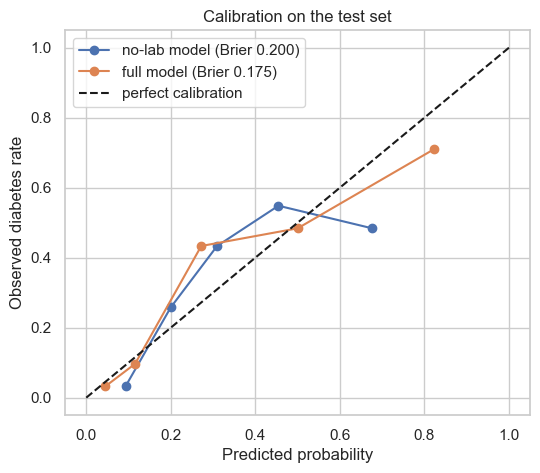

no-lab model: mean predicted risk 0.347 vs actual rate 0.351
full model: mean predicted risk 0.352 vs actual rate 0.351


In [6]:
fig, ax = plt.subplots(figsize=(6, 5))
for name in ["no-lab model", "full model"]:
    frac_pos, mean_pred = calibration_curve(y_test, scores[name], n_bins=5, strategy="quantile")
    ax.plot(mean_pred, frac_pos, "o-", label=f"{name} (Brier {brier_score_loss(y_test, scores[name]):.3f})")
ax.plot([0, 1], [0, 1], "k--", label="perfect calibration")
ax.set_xlabel("Predicted probability")
ax.set_ylabel("Observed diabetes rate")
ax.set_title("Calibration on the test set")
ax.legend()
plt.show()
for name in ["no-lab model", "full model"]:
    print(f"{name}: mean predicted risk {scores[name].mean():.3f} vs actual rate {y_test.mean():.3f}")

- **On average** both models are well calibrated: mean predicted risk ≈ 0.35, and the actual rate is 0.35.
- At the **high end** they **overestimate**: where the no-lab model predicts ~68 %, only ~48 % have diabetes, and the full model
  predicts ~82 % where ~71 % have diabetes. In the middle range they slightly underestimate. With ~30 patients per bin this is noisy,
  but it matches a known weakness of small datasets.
- **Consequence for the app:** show **risk bands** (lower / moderate / higher) together with the referral suggestion, rather
  than a precise percentage that implies more certainty than the data supports.

## 5. Error analysis: who does the full model miss?
Using the full model at its matched-rate threshold, we compare the **missed** diabetes cases with the ones it **caught**.

In [7]:
t_full = meta["models"]["full"]["thresholds"]["matched_rate"]
cases = test[test[TARGET] == 1].copy()
cases["risk"] = scores["full model"][test[TARGET].to_numpy() == 1]
cases["caught"] = cases["risk"] >= t_full
print(f"Diabetes cases in test: {len(cases)}, caught: {cases.caught.sum()}, missed: {(~cases.caught).sum()}\n")
profile = cases.groupby("caught")[["Glucose", "BMI", "Age", "Pregnancies", "DiabetesPedigree", "risk"]].median().T
profile.columns = ["missed (median)", "caught (median)"]
profile.round(2)

Diabetes cases in test: 54, caught: 30, missed: 24



,missed (median),caught (median)
Glucose,122.00,154.50
BMI,31.40,36.60
Age,31.50,38.00
Pregnancies,4.00,4.50
DiabetesPedigree,0.33,0.44
risk,0.31,0.78


In [8]:
print("Glucose of missed cases:", sorted(cases.loc[~cases.caught, "Glucose"].dropna().astype(int).tolist()))
print("Missed cases with glucose < 140 mg/dL:", int((cases.loc[~cases.caught, "Glucose"] < 140).sum()), "of", int((~cases.caught).sum()))

Glucose of missed cases: [78, 90, 104, 106, 107, 109, 112, 113, 114, 114, 119, 121, 123, 124, 124, 124, 124, 125, 128, 129, 131, 132, 148, 149]
Missed cases with glucose < 140 mg/dL: 22 of 24


- The missed cases have **much lower glucose** (median 122 vs 155 mg/dL), lower BMI and are younger. In other words, they don't *look* diabetic
  in the measurements we have.
- **22 of the 24 missed cases had a 2-hour glucose below 140 mg/dL**, which is the normal range for this test.
- Why can someone with normal glucose be labelled positive? The dataset defines a positive case as diabetes found
  **at any survey examination** or in routine care, while the features come from a single examination. A likely explanation, which this
  dataset can't confirm, is that many of these women **developed diabetes later**. No model can catch that from these measurements.
- **Practical implication:** a negative screen is not a clean bill of health. The app must say so, and repeat screening matters.

## 6. Subgroup check: does performance differ by age?
A screening tool that works well for older patients but misses younger ones would be a fairness and safety problem.
The groups are small, so this is a **warning check, not proof**.

In [9]:
test_groups = pd.cut(test["Age"], bins=[20, 29, 44, 100], labels=["21–29", "30–44", "45+"])
rows = []
for g in test_groups.cat.categories:
    mask = (test_groups == g).to_numpy()
    yg = y_test[mask]
    row = {"age group": g, "patients": int(mask.sum()), "with diabetes": int(yg.sum())}
    for key, label in [("no_lab", "no-lab model"), ("full", "full model")]:
        t = meta["models"][key]["thresholds"]["matched_rate"]
        row[f"{label}: sensitivity"] = ((scores[label][mask] >= t) & (yg == 1)).sum() / max(yg.sum(), 1)
    row["rule: sensitivity"] = ((scores["guideline rule"][mask] == 1) & (yg == 1)).sum() / max(yg.sum(), 1)
    rows.append(row)
pd.DataFrame(rows).set_index("age group").round(2)

,patients,with diabetes,no-lab model: sensitivity,full model: sensitivity,rule: sensitivity
age group,,,,,
21–29,85,16,0.25,0.38,0.00
30–44,40,26,0.50,0.58,0.62
45+,29,12,0.92,0.75,1.00


**This is the most important finding of the evaluation.**
- **Young women (21–29) are mostly missed by everything.** The rule catches **0 of 16** (by design, because it requires age ≥ 35),
  the no-lab model **4 of 16** and the full model **6 of 16**.
- For **45+**, the rule catches **all 12** cases, more than either model.
- So the rule and the models catch about the **same number** of cases overall, but **different people**: the rule concentrates all its
  referrals on older women, while the models spread theirs across ages.
- Caveat: these groups are tiny (16, 26 and 12 cases), so the exact numbers are very uncertain. And this subgroup check was not
  one of the pre-set success criteria, so it's an **exploratory finding** to be confirmed on more data, not a proven result.
- Still, the direction matters for safety and fairness: an age-gated screening rule **structurally cannot** catch young patients.

## 7. Final verdicts
| Question | Pre-set success criterion | Test result (95 % CI) | Verdict |
|---|---|---|---|
| 1. No-lab model vs guideline rule | More cases caught at the same referral rate, CI excludes 0 | −5.6 points (−14.3 to +6.0) | ❌ **Not met.** No evidence it is better. |
| 2. Full model vs glucose alone | Higher ROC-AUC, CI excludes 0 | +0.048 (+0.004 to +0.095) | ✅ **Met**, with a modest margin |
| 3. Value of the lab test | Descriptive | ROC-AUC 0.73 → 0.81. At ~53–55 % referral: 13 → 7 missed cases | Lab values help most when the goal is to miss few cases |

**What we can honestly claim**
1. **Quick measurements alone don't beat the simple guideline rule** at the guideline's referral rate. This is a negative result,
   consistent across cross-validation and the test set, and a useful one: a clinic shouldn't expect a model like this to outperform
   the rule it already has.
2. **When glucose and insulin are available**, combining them with the other measurements ranks patients better than glucose alone, though the gain may be small.
3. **The age-gated rule never refers women under 35**, so it misses every young case. The models catch some (exploratory, small numbers).
4. **Most missed cases had normal glucose at the exam**, which suggests later-onset diabetes that no single-visit model can predict.

**Limitations**
- Small test set (154 patients, 54 cases), so the confidence intervals are wide.
- One population (Pima women, 1980s) and a label that mixes current and later diagnosis.
- The guideline rule is a simplification of real screening guidance, and the USPSTF wording should be checked before citing.

**Implications for Stage 4 (the app)**
- Present the tool as **decision support for a referral**, with risk **bands** rather than precise percentages, and a clear note that a low score is not a diagnosis.
- Offer both the matched-rate and high-sensitivity thresholds, and explain the trade-off (more referrals ↔ fewer missed cases).
- Explicitly mention that young patients can be missed.